# Committor Model: 1D Low-Friction Langevin Dynamics, with History

Trains a non-parametric committor (`CommittorNE`) on a long underdamped Langevin trajectory of a particle in 1D. At low friction the committor depends on position and velocity, q(λ, v), but only λ is given to the model. The velocity enters through the history: with lag d = 1 the basis is a polynomial in (λ(t−1), λ(t)), and with one frame per MD step that is equivalent to λ and the finite-difference velocity (λ(t) − λ(t−1))/dt.

**Data:** `md_istarwell2_100M/md_path.npy` (100M frames, one per step of dt = 0.005, columns λ and v; converted from `md_path.txt`). Friction γ = 1, kT = 1, m = 1.

**Potential:** `CosWellWalls`, a well of depth 1.2 kT on [−0.25, 0.25], flanked by 0.15 kT bumps and flat regions, with harmonic walls (k = 100) beyond ±0.45.

**Boundaries:** `λ <= -0.35` (A) and `λ >= 0.35` (B), the outer iSTAR interfaces

## 1. Imports

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import cupy as cp

# Plot styling
plt.rc('font', size=10)
plt.rc('axes', titlesize=14)
plt.rc('axes', labelsize=14)
plt.rc('xtick', labelsize=12)
plt.rc('ytick', labelsize=12)
plt.rc('legend', fontsize=12)

# Custom optimal-RC / committor package
import sys
sys.path.insert(0, '/mnt/0bf0c339-34bb-4500-a5fb-f3c2a863de29/DATA/OP_improvement/optimalrcs/optimalrcs-cupy/')
import optimalrcs, metrics, plots

## 2. Data Loading

Loads the first `n_frames` frames (5M frames contain about 8000 A↔B transitions). The velocity `v` is only used to check the result in section 6, not in training.

In [2]:
SRC = '/mnt/0bf0c339-34bb-4500-a5fb-f3c2a863de29/DATA/PyRETIS3/toytis/simulations/md_istarwell2_100M'
n_frames = 6_000_000

data = np.load(f'{SRC}/md_path.npy', mmap_mode='r')[:n_frames]
lam, v = np.array(data[:, 0]), np.array(data[:, 1])
lambda_a, lambda_b = -0.35, 0.35
dt = 0.005                         # MD time step = time per frame
print(f'Frames: {len(lam)}')

Frames: 6000000


## 3. Free Energy Profile (FEP)

FEP along λ: the central well between the two small bumps.

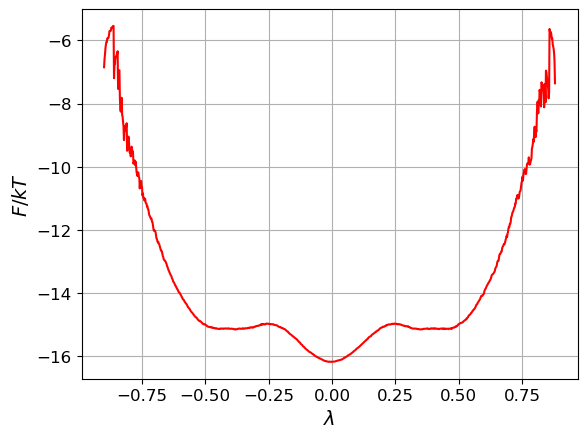

In [3]:
fig, ax = plt.subplots(1, 1)
plots.plot_fep(ax, cp.asarray(lam), xlabel='$\\lambda$')
plt.show()

## 4. Trajectory Indices

Single trajectory (`i_traj = 1` for all frames).

In [4]:
i_traj = np.ones_like(lam)          # trajectory index (1 = single trajectory)
t_traj = np.arange(len(lam))        # frame index

## 5. Train Committor (Non-Parametric, with History)

`CommittorNE` rather than the equilibrium `Committor`: time reversal flips the velocity, so the reversible estimator does not apply to q(λ, v). The CV `y` is λ.

With `history_type = ['y(t-d),y(t)']` each iteration draws a lag d from `history`:
- d = 0: basis in (r(t), λ(t)), the usual update
- d = 1: basis in (λ(t−1), λ(t)), which carries the velocity

**Parameters:**
| Parameter | Value | Description |
|-----------|-------|-------------|
| `history` | 0, 1 | History lag times |
| `history_type` | `y(t-d),y(t)` | Feature types |
| `envelope_scale` | 0.001 | RC envelope width |
| `gamma` | 0.2 | RC regularization; with gamma = 0 the fit does not converge here |
| `ny` | 6 | Polynomial degree |
| `max_iter` | 1500 | Maximum iterations |

In [ ]:
optimalrcs.envelope_scale = 0.001
history = [0, 1]                   # lag times
gamma = 0.1                        # regularization strength
yr_type = ['y(t-d),y(t)']          # lambda(t-d) and lambda(t)
y = cp.asarray(lam)
Y = cp.asarray(np.c_[lam, v])  # 2D input for committor
np.random.seed(0); cp.random.seed(0)

q = optimalrcs.CommittorNE(
    boundary0=lam <= lambda_a,     # state A
    boundary1=lam >= lambda_b,     # state B
    i_traj=i_traj,
    t_traj=t_traj,
)

q.fit_transform(
    lambda: Y[:, np.random.randint(2)],
    # history_delta_t=history,
    # history_type=yr_type,
    gamma=gamma,
    ny=6,
    max_iter=30000,
    print_step=250,
    save_min_delta_zq=False,
)

# Diagnostics: metrics, FEPs + Z_q, observed vs predicted
q.plots_metrics(['cross_entropy', 'max_sd_zq', 'delta_r2'])
plt.show()
q.plots_feps(delta_t_sim=dt)
q.plots_obs_pred()

#=0, xent=0.505398, mse=0.177746, sdzq=811.382, dzq=2044.14, dr2=174.964, auc=0.795194, |dx|=0.168632, time=3.24896
#=250, xent=0.504669, mse=0.177024, sdzq=701.821, dzq=1786.14, dr2=169.559, auc=0.79555, |dx|=0.00815054, time=106.748
#=500, xent=0.504651, mse=0.177021, sdzq=701.603, dzq=1784.86, dr2=169.534, auc=0.795553, |dx|=0.000235707, time=217.44
#=750, xent=0.504647, mse=0.177019, sdzq=701.346, dzq=1783.89, dr2=169.52, auc=0.795553, |dx|=7.70583e-05, time=327.332


KeyboardInterrupt: 

## 6. Committor in the (λ, v) Plane

Mean q per (λ, v) bin, using the true velocity from the MD. If the history captured the velocity, q depends on v and not only on λ: particles moving towards B have higher q.

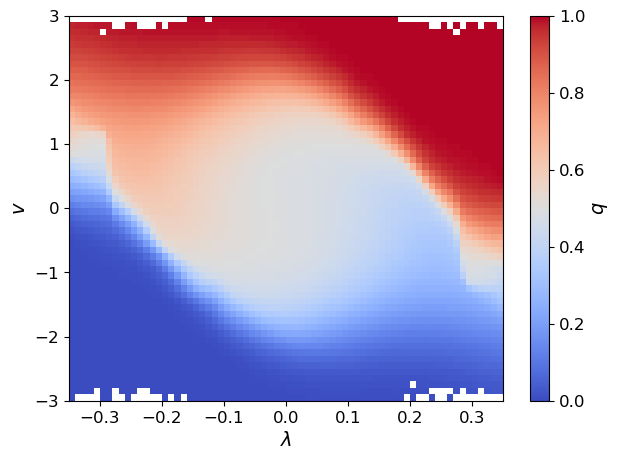

In [8]:
r = cp.asnumpy(q.r_traj)
edges_l = np.linspace(lambda_a, lambda_b, 71)
edges_v = np.linspace(-3, 3, 61)
n, _, _ = np.histogram2d(lam, v, [edges_l, edges_v])
s, _, _ = np.histogram2d(lam, v, [edges_l, edges_v], weights=r)
q_lv = np.where(n > 20, s / np.maximum(n, 1), np.nan)

fig, ax = plt.subplots(1, 1, figsize=(7, 5))
im = ax.pcolormesh(edges_l, edges_v, q_lv.T, cmap='coolwarm', vmin=0, vmax=1)
fig.colorbar(im, ax=ax, label='$q$')
ax.set(xlabel='$\\lambda$', ylabel='$v$')
plt.show()

## 7. Save Results

Uncomment to save the raw committor trajectory to disk.

In [9]:
np.save('q_traj_langevin_env0.001g0.2.npy', cp.asnumpy(q.r_traj))